# 03 · Math and Code Together — Sample Cases from the Final Method

**Project:** SVD-based digital watermarking & steganography (course 01076032)

**What this notebook answers:** *Which mathematics does the code use, where, and what does it produce on real cases?*
Every cell calls the final implementation in `src/svdmark` (the same code the demo and the tests use), so nothing here is a separate copy of the method.
The map from each formula to its function is in [`docs/MATH_MAP.md`](../docs/MATH_MAP.md); the one-shot version of the last section is `examples/ex7_many_cases.py`.

**Words used throughout** (each is explained again where it first appears):

| Term | Meaning |
|---|---|
| image matrix `A` | a grid of numbers; each number is the brightness of one pixel, 0 (black) to 255 (white) |
| `σ₁ ≥ σ₂ ≥ …` (sigma) | singular values of a matrix: non-negative numbers that say how strong each layer of the matrix is, largest first |
| `Δ` (delta) | the step size used when hiding a bit; bigger means stronger against damage but a bigger change to the picture |
| `b` | block size: the picture is cut into `b × b` squares and each square hides one bit |
| PSNR | picture quality in dB after a change: higher means the changed picture looks closer to the original (about 40 dB and above is hard to see) |
| BER | bit error rate: wrong bits ÷ all bits |
| attack | any change made to the picture after hiding (JPEG save, noise, crop, blur, rotate) |

In [1]:
import sys
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
for p in (ROOT / "src", ROOT / "examples"):          # works even if the package is not pip-installed
    if str(p) not in sys.path:
        sys.path.insert(0, str(p))

from svdmark import attacks, ecc, stego, watermark
from svdmark.data import load_gray
from svdmark.metrics import ber, ncc, psnr
from svdmark.svd_utils import energy, reconstruct, svd, svd_2x2_by_hand
import ex7_many_cases as ex7                          # case helpers shared with examples/ex7_many_cases.py

plt.rcParams.update({"figure.dpi": 90, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titlesize": 10, "axes.labelsize": 9})
warnings.simplefilter("ignore", RuntimeWarning)

A = load_gray(ROOT / "data/images/train/249061.jpg").astype(float)   # one photo used in most cells
print("photo 249061.jpg as a matrix:", A.shape, "(rows × columns), values", A.min(), "to", A.max())

photo 249061.jpg as a matrix: (320, 480) (rows × columns), values 32.0 to 254.0


## 1. Vectors, norm and NCC

*Where it is used:* `metrics.ncc` compares the logo that was hidden with the logo that was read back.
A **norm** `‖v‖ = √(v·v)` is the length of a vector. The **dot product** `⟨v, w⟩` multiplies matching entries and adds them up.
**NCC** (normalised correlation) is `⟨w, w*⟩ / (‖w‖ ‖w*‖)`: 1 means the two point the same way, 0 means unrelated.

In [2]:
W      = np.array([[1, 0, 1], [0, 1, 0], [1, 0, 1]])      # a 3×3 logo
W_star = np.array([[0, 0, 1], [0, 0, 0], [1, 0, 0]])      # a damaged copy of it
print("‖(1,1,1)‖        =", round(np.linalg.norm([1, 1, 1]), 4))
print("⟨W, W*⟩          =", int(W.ravel() @ W_star.ravel()))
print("NCC(W, W*)       =", round(ncc(W, W_star), 3), "  = 2 / (√5 · √2)")
print("a + b (mod 2)    =", (np.array([1, 0, 1, 1]) + np.array([1, 1, 0, 1])) % 2, "  (bits add with 1+1=0)")

‖(1,1,1)‖        = 1.7321
⟨W, W*⟩          = 2
NCC(W, W*)       = 0.632   = 2 / (√5 · √2)
a + b (mod 2)    = [0 1 1 0]   (bits add with 1+1=0)


## 2. SVD: layers of a matrix

*Where it is used:* `svd_utils.svd`, `svd_utils.reconstruct`, `svd_utils.energy`.
The **SVD** (singular value decomposition) writes a matrix as `A = U · diag(σ) · Vᵀ = σ₁u₁v₁ᵀ + σ₂u₂v₂ᵀ + …`:
a stack of simple layers, strongest first. The **energy** `Σσᵢ²` equals the sum of all squared entries of `A`.

**By hand on a 2×2 matrix.** `σᵢ = √(eigenvalue of AᵀA)` — `svd_2x2_by_hand` follows exactly the steps of the report (section 4.2).

In [3]:
M = np.array([[3.0, 0.0], [4.0, 5.0]])
U, s, Vt = svd_2x2_by_hand(M)
print("AᵀA =\n", M.T @ M)
print("σ by hand =", np.round(s, 4), "  σ by numpy =", np.round(svd(M)[1], 4))
print("rebuilt from the layers =\n", np.round(reconstruct(U, s, Vt), 6))
print("sum of squared entries =", float(np.sum(M**2)), "   σ₁² + σ₂² =", round(energy(s), 6))

AᵀA =
 [[25. 20.]
 [20. 25.]]
σ by hand = [6.7082 2.2361]   σ by numpy = [6.7082 2.2361]
rebuilt from the layers =
 [[3. 0.]
 [4. 5.]]
sum of squared entries = 50.0    σ₁² + σ₂² = 50.0


**On a real photo.** Almost all of a picture sits in the first few layers. Here the photo is rebuilt from only its first `k` layers.
The right panel shows why `σ₁` is a good place to hide data: it is far larger than the rest.

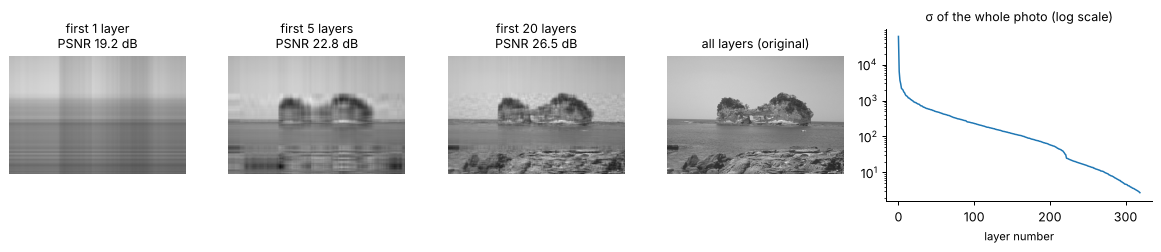

σ₁ = 60552, σ₂ = 6426, σ₁ holds 96.8% of the energy


In [4]:
U, s, Vt = svd(A)
fig, ax = plt.subplots(1, 5, figsize=(13, 2.9), gridspec_kw={"width_ratios": [1, 1, 1, 1, 1.5]})
for a, k in zip(ax[:4], (1, 5, 20, len(s))):
    R = (U[:, :k] * s[:k]) @ Vt[:k]
    a.imshow(np.clip(R, 0, 255), cmap="gray", vmin=0, vmax=255)
    a.set_title(f"first {k} layer{'s' if k > 1 else ''}\nPSNR {psnr(A, np.clip(R,0,255)):.1f} dB" if k < len(s) else "all layers (original)")
    a.axis("off")
ax[4].semilogy(s, lw=1.2)
ax[4].set_title("σ of the whole photo (log scale)")
ax[4].set_xlabel("layer number")
plt.tight_layout(); plt.show()
print(f"σ₁ = {s[0]:.0f}, σ₂ = {s[1]:.0f}, σ₁ holds {s[0]**2 / energy(s):.1%} of the energy")

## 3. Hiding one bit: QIM on `σ₁`

*Where it is used:* `stego.extract_bit` (read) and `stego.embed_value` (write).
The σ axis is cut into intervals of width `Δ`. With `q = ⌊σ / Δ⌋`, the **bit is the parity of `q`** (`q mod 2`).
To write a bit, `σ₁` is moved to the **centre** of the nearest interval whose parity is the wanted bit, so later damage up to `Δ/2` either way still reads back right.

**The small example from the report (section 4.3):** a 2×2 block, `Δ = 6`, hide bit 1.

σ₁ = 113.687 → interval q = 18 → bit 0
move σ₁ to the centre of the nearest odd interval: 117.0
block after rounding to integers:
 [[54. 57.]
 [63. 61.]]
receiver measures σ₁ = 117.68 → bit 1   PSNR 42.11 dB


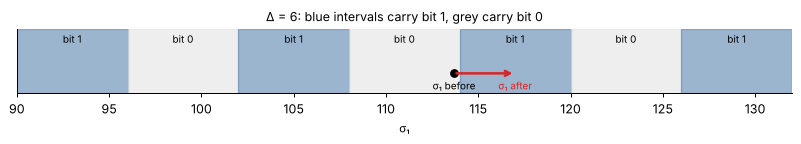

In [5]:
B = np.array([[52.0, 55.0], [61.0, 59.0]])
U, s, Vt = svd(B)
delta = 6
print(f"σ₁ = {s[0]:.3f} → interval q = {int(s[0] // delta)} → bit {stego.extract_bit(s[0], delta)}")
s_new = s.copy(); s_new[0] = stego.embed_value(s[0], 1, delta)
print(f"move σ₁ to the centre of the nearest odd interval: {s_new[0]}")
B_new = reconstruct(U, s_new, Vt)
B_int = np.rint(B_new)                                # a real image stores whole numbers
print("block after rounding to integers:\n", B_int)
s_read = svd(B_int)[1][0]
print(f"receiver measures σ₁ = {s_read:.2f} → bit {stego.extract_bit(s_read, delta)}   PSNR {psnr(B, B_int):.2f} dB")

fig, ax = plt.subplots(figsize=(9, 1.7))
for q in range(15, 22):
    ax.axvspan(q * delta, (q + 1) * delta, color="#4c78a8" if q % 2 else "#e0e0e0", alpha=.55)
    ax.text((q + .5) * delta, .78, f"bit {q % 2}", ha="center", fontsize=8)
ax.annotate("", xy=(s_new[0], .3), xytext=(s[0], .3), arrowprops=dict(arrowstyle="->", lw=2, color="#d62728"))
ax.plot([s[0]], [.3], "ko"); ax.text(s[0], .05, "σ₁ before", ha="center", fontsize=8)
ax.text(s_new[0], .05, "σ₁ after", ha="center", fontsize=8, color="#d62728")
ax.set_xlim(15 * delta, 22 * delta); ax.set_ylim(0, 1); ax.set_yticks([]); ax.set_xlabel("σ₁")
ax.set_title("Δ = 6: blue intervals carry bit 1, grey carry bit 0")
plt.tight_layout(); plt.show()

**Why rounding matters.** A picture stores whole numbers, so the block is rounded after the change and `σ₁` moves a little (117 → 117.68 above).
`stego.embed_bits` therefore *reads the bit back exactly as the receiver will* (closed-loop check) and only accepts a block when `σ₁` lands at least `Δ/4` away from both interval edges.
The next cell does this for one real 8×8 block with the final setting `Δ = 32`.

In [6]:
blk = stego.to_blocks(A, 8)[100]
for want in (0, 1):
    res = stego.embed_bits(blk, [want], delta=32.0, b=8)
    got = stego.extract_bits(res.image, 1, delta=32.0, b=8)
    s0, s1 = np.linalg.svd(blk, compute_uv=False)[0], np.linalg.svd(res.image, compute_uv=False)[0]
    print(f"want bit {want}: σ₁ {s0:7.2f} → {s1:7.2f}   read back {got[0]}   "
          f"largest pixel change {np.abs(res.image - blk).max():.0f}   failed blocks {res.n_failed}")

want bit 0: σ₁ 1434.15 → 1426.15   read back 0   largest pixel change 1   failed blocks 0
want bit 1: σ₁ 1434.15 → 1458.15   read back 1   largest pixel change 3   failed blocks 0


## 4. A whole message in a whole photo

*Where it is used:* `stego.embed_text` / `stego.extract_text`, built from the pieces below.
- **Blocks:** `stego.to_blocks` cuts the photo into `b × b` squares in reading order, one bit each. Capacity = `(height/b) · (width/b)` bits.
- **Frame:** `stego.text_to_bits` writes `length (16 bit) | CRC (16 bit) | UTF-8 text`. The **CRC** is a check number computed from the length and the text; if one bit changes, the CRC no longer matches and the receiver knows the message is damaged.
- **Secret key:** `stego._key_seed` / `stego._dither` turn a password into a different small shift of the interval grid for every block (PBKDF2-HMAC-SHA256, a deliberately slow function so guessing passwords is slow).

message "นัดบ่ายสามที่ตึก 12" = 51 bytes → 440 bits = 32 header + 8 × 51
first 32 bits (length | CRC): 0000000000110011 | 1111000100011000
capacity of this photo at b = 8: 2400 bits = 296 bytes of text


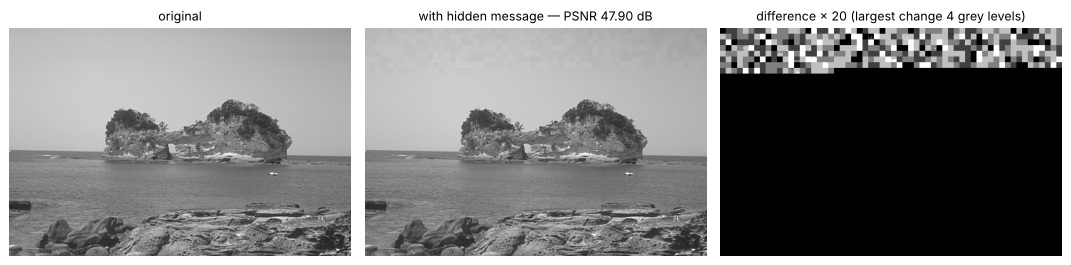

blocks changed: 394. The message needs 440 bits, so only the first 440 of 2400 blocks carry one; 46 of those already held the right bit, and the other 1960 blocks are untouched


In [7]:
msg = ex7.MSG
bits = stego.text_to_bits(msg)
print(f'message "{msg}" = {len(msg.encode())} bytes → {len(bits)} bits = 32 header + 8 × {len(msg.encode())}')
print("first 32 bits (length | CRC):", "".join(map(str, bits[:16])), "|", "".join(map(str, bits[16:32])))
print("capacity of this photo at b = 8:", stego.capacity(A.shape, 8), "bits =", stego.text_capacity_bytes(A.shape, 8), "bytes of text")

res = stego.embed_text(A, msg, key="kmitl")
stego_img = res.image
d = np.abs(stego_img - A)
fig, ax = plt.subplots(1, 3, figsize=(12, 3.3))
ax[0].imshow(A, cmap="gray", vmin=0, vmax=255); ax[0].set_title("original")
ax[1].imshow(stego_img, cmap="gray", vmin=0, vmax=255); ax[1].set_title(f"with hidden message — PSNR {psnr(A, stego_img):.2f} dB")
ax[2].imshow(np.clip(d * 20, 0, 255), cmap="gray"); ax[2].set_title(f"difference × 20 (largest change {d.max():.0f} grey levels)")
for a in ax: a.axis("off")
plt.tight_layout(); plt.show()
changed = int((stego.to_blocks(d, 8).reshape(-1, 64).max(axis=1) > 0).sum())
print(f"blocks changed: {changed}. The message needs {len(bits)} bits, so only the first {len(bits)} of {stego.capacity(A.shape, 8)} blocks carry one; {len(bits) - changed} of those already held the right bit, and the other {stego.capacity(A.shape, 8) - len(bits)} blocks are untouched")

In [8]:
rows = []
for name, img, key in [("right key", stego_img, "kmitl"), ("wrong key (kmit1)", stego_img, "kmit1"),
                       ("no key", stego_img, None), ("original photo, never used", A, "kmitl")]:
    text, status = stego.extract_text(img, key=key)
    rows.append([name, status, text])
display(pd.DataFrame(rows, columns=["reader", "status", "text read"]).fillna("—"))
print("status: ok = CRC matches | damaged = header fits but CRC fails | no_message = header makes no sense")

,reader,status,text read
0,right key,ok,นัดบ่ายสามที่ตึก 12
1,wrong key (kmit1),no_message,—
2,no key,no_message,—
3,"original photo, never used",no_message,—


status: ok = CRC matches | damaged = header fits but CRC fails | no_message = header makes no sense


## 5. Error correction: Hamming(7,4)

*Where it is used:* `ecc.encode`, `ecc.decode`, switched on with `embed_text(..., ecc=True)`.
One wrong bit makes the CRC fail and the whole message is refused. Hamming(7,4) adds 3 check bits to every 4 data bits: `c = d·G (mod 2)`.
The receiver computes the **syndrome** `s = H·rᵀ (mod 2)`; if `s` equals column `j` of `H`, bit `j` is wrong and is flipped back. One error per 7-bit word is fixed.

In [9]:
d = np.array([1, 0, 1, 1]); c = ecc.encode(d)
r = c.copy(); r[2] ^= 1                                  # flip bit number 3
syn = (r @ ecc.H.T) % 2
print("data", d, "→ codeword", c, "   G·Hᵀ = 0 (mod 2):", bool(((ecc.G @ ecc.H.T) % 2 == 0).all()))
print("received", r, "  syndrome", syn, "= column 3 of H:", ecc.H[:, 2])
fixed, n = ecc.decode(r)
print("decoded", fixed, "  bits corrected:", n)

data [1 0 1 1] → codeword [1 0 1 1 0 1 0]    G·Hᵀ = 0 (mod 2): True
received [1 0 0 1 0 1 0]   syndrome [0 1 1] = column 3 of H: [0 1 1]
decoded [1 0 1 1]   bits corrected: 1


**Does it help on a real attack?** The message is hidden in `capacity` mode (`b = 4`, `Δ = 16`, many small blocks, weakest) and the picture is saved as JPEG at falling quality (lower number = more damage).
This is **one photo, one message** — it shows the mechanism. The statistics over 400 photos are in `results/findings.md`.

In [10]:
qs = [95, 90, 80, 75, 70, 60, 50]
rows = []
for q in qs:
    row = {"JPEG quality": q}
    for use_ecc in (False, True):
        r_ = ex7.stego_case("", A, mode="capacity", attack=("jpeg", q), ecc=use_ecc)
        row["ECC on" if use_ecc else "ECC off"] = f"{r_[5]} ({r_[3]} wrong)"
    rows.append(row)
display(pd.DataFrame(rows).set_index("JPEG quality"))
print("wrong = bits read back differently from the bits hidden, counted BEFORE Hamming correction; with ECC there are 770 bits instead of 440 because 3 check bits are added per 4 data bits.")

,ECC off,ECC on
JPEG quality,,
95,ok (0/440 wrong),ok (0/770 wrong)
90,ok (0/440 wrong),ok (0/770 wrong)
80,ok (0/440 wrong),ok (0/770 wrong)
75,ok (0/440 wrong),ok (1/770 wrong)
70,ok (0/440 wrong),ok (1/770 wrong)
60,damaged (15/440 wrong),ok (16/770 wrong)
50,damaged (16/440 wrong),damaged (31/770 wrong)


wrong = bits read back differently from the bits hidden, counted BEFORE Hamming correction; with ECC there are 770 bits instead of 440 because 3 check bits are added per 4 data bits.


## 6. Watermark: `D = S + αW`

*Where it is used:* `watermark.embed`, `watermark.extract`, `watermark.shift_score` (Liu–Tan method, 2002).
Let `A = U S Vᵀ` (`S` = diagonal matrix of σ) and `W` the logo. Then `D = S + αW`, `D = U_w S_w V_wᵀ`, and the marked picture is `A_w = U S_w Vᵀ`.
`α` (alpha) is how strongly the logo is mixed in. To read it back from a received picture: `D* = U_w · diag(σ*) · V_wᵀ`, `W* = (D* − S) / α`.
Two scores are shown: **NCC** between `W` and `W*`, and our **shift** score `cos(σ(received) − S, S_w − S)`, which asks whether the singular values moved the way embedding moves them.

logo (320, 320), marked photo PSNR 46.92 dB


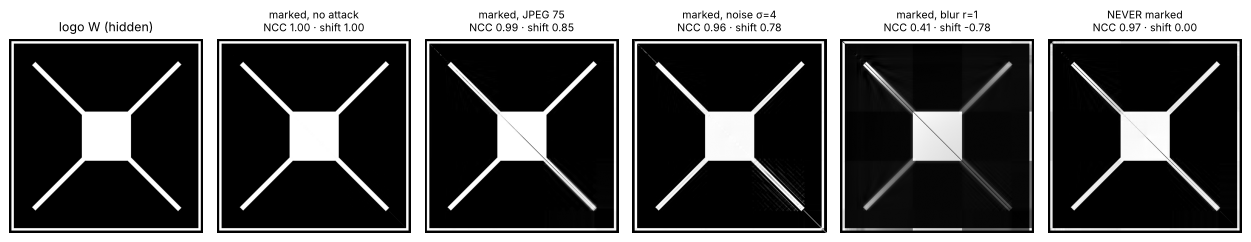

In [11]:
W = ex7.make_logo(min(A.shape))
Aw, key = watermark.embed(A, W, alpha=16.0)
Au = np.clip(np.rint(Aw), 0, 255)
print(f"logo {W.shape}, marked photo PSNR {psnr(A, Au):.2f} dB")

cases = [("marked, no attack", Au), ("marked, JPEG 75", attacks.apply("jpeg", Au, 75, seed=1)),
         ("marked, noise σ=4", attacks.apply("noise", Au, 4, seed=1)), ("marked, blur r=1", attacks.apply("blur", Au, 1.0, seed=1)),
         ("NEVER marked", A)]
fig, ax = plt.subplots(1, len(cases) + 1, figsize=(14, 2.9))
ax[0].imshow(W, cmap="gray"); ax[0].set_title("logo W (hidden)"); ax[0].axis("off")
out = []
for a, (name, img) in zip(ax[1:], cases):
    Wx = watermark.extract(img, key)
    n_, sh = ncc(W, Wx), watermark.shift_score(img, key)
    a.imshow(np.clip(Wx, 0, 1), cmap="gray", vmin=0, vmax=1); a.axis("off")
    a.set_title(f"{name}\nNCC {n_:.2f} · shift {sh:.2f}", fontsize=8.5)
    out.append((name, n_, sh))
plt.tight_layout(); plt.show()

**Reading the pictures.** The last panel is a photo that was *never marked*, yet the logo still appears and NCC stays high: the logo is stored in the key (`U_w`, `V_w`), so NCC alone cannot tell "marked" from "not marked".
The shift score does: it is about 0 for the unmarked photo and close to 1 for the marked one. After heavy blur even shift fails (a stated limit, `results/findings.md`).

**Strength `α`.** A larger `α` survives more damage but changes the picture more.

In [12]:
rows = []
for alpha in (2, 4, 8, 16, 32):
    r1 = ex7.wm_case("", A, alpha=alpha)
    r2 = ex7.wm_case("", A, alpha=alpha, attack=("jpeg", 75))
    r3 = ex7.wm_case("", A, alpha=alpha, target="original")
    rows.append([alpha, r1[2], r2[5], r3[5]])
display(pd.DataFrame(rows, columns=["α", "PSNR dB", "shift after JPEG 75 (marked)", "shift on never-marked"]).set_index("α"))

,PSNR dB,shift after JPEG 75 (marked),shift on never-marked
α,,,
2,74.52,-0.340,0.000
4,60.69,-0.083,0.000
8,53.58,0.437,0.000
16,46.92,0.851,0.000
32,38.09,0.984,0.000


## 7. Everything at once

The same tables as `python examples/ex7_many_cases.py`: 13 hiding cases, 7 watermark cases, and the same message on 6 different photos.
Cases that fail are kept on purpose (rotate 0.5°, blur): they are the limits of the method.

In [13]:
ex7.part_a(A)
ex7.part_b(A)
ex7.part_c()


PART A  steganography, photo 249061.jpg 480x320, message "นัดบ่ายสามที่ตึก 12" (51 bytes)
case                           PSNR dB  attack     wrong bits  fixed  status      text same
-------------------------------------------------------------------------------------------
A1 balanced, no attack         47.90    none       0/440       0      ok          yes      
A2 right key                   47.90    none       0/440       0      ok          yes      
A3 wrong key (kmit1)           47.90    none       209/440     0      no_message  no       
A4 no key given                47.90    none       218/440     0      no_message  no       
A5 never-hidden photo          inf      none       -           0      no_message  no       
A6 JPEG 90                     47.90    jpeg90     0/440       0      ok          yes      
A7 JPEG 50                     47.90    jpeg50     0/440       0      ok          yes      
A8 noise std 4                 47.90    noise4     0/440       0      ok         


PART B  watermark D = S + alpha*W (Liu-Tan), same photo
case                             alpha  PSNR dB  attack     NCC    shift   verdict   
-------------------------------------------------------------------------------------
B1 embed, no attack              16     46.92    none       1.000  0.999   mark found
B2 never-marked photo            16     46.92    none       0.975  0.000   no mark   
B3 JPEG 75                       16     46.92    jpeg75     0.993  0.851   mark found
B4 alpha too weak (2) + JPEG 75  2      74.52    jpeg75     0.809  -0.340  no mark   
B5 rotate 1 deg                  16     46.92    rotate1.0  0.984  0.728   unsure    
B6 blur radius 1                 16     46.92    blur1.0    0.406  -0.778  no mark   
B7 noise std 4                   16     46.92    noise4     0.965  0.779   unsure    

NCC = how much the extracted logo looks like the real one (it is high even for B2: the key itself holds the logo).
shift = cos(sigma(received) - S, Sw - S): near 1 if t

## 8. Summary: formula → code

| Math | Code | Section |
|---|---|---|
| norm, dot product, NCC | `metrics.ncc` | 1, 6 |
| SVD, σ, energy, rebuild | `svd_utils.svd`, `energy`, `reconstruct` | 2 |
| QIM parity rule | `stego.extract_bit`, `embed_value` | 3 |
| blocks, capacity, closed-loop check | `stego.to_blocks`, `capacity`, `embed_bits` | 3, 4 |
| key → grid shift (PBKDF2) | `stego._key_seed`, `_dither` | 4 |
| CRC-16 frame | `stego.text_to_bits`, `bits_to_text` | 4 |
| Hamming(7,4) over mod 2 | `ecc.encode`, `ecc.decode` | 5 |
| Liu–Tan `D = S + αW` | `watermark.embed`, `extract` | 6 |
| shift score | `watermark.shift_score` | 6 |
| PSNR, BER | `metrics.psnr`, `ber` | all |

**Limits stated honestly:** results above are for the photos named in each cell; the averages over 400 photos (PSNR 40.7 dB with a message that fills the photo, message survival rates, detector AUC) are in `results/findings.md`. Rotation and strong blur are not survived.